<a href="https://colab.research.google.com/github/mdd214/CDS230-Lab8/blob/main/mushroom_nb_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hyunwoo Sun, Sungil Moon

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Upload Mushroom dataset
uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df['class'].value_counts())


Saving mushroom.csv to mushroom.csv
Dataset shape: (8124, 23)

Class distribution:
class
e    4208
p    3916
Name: count, dtype: int64


Missing values:
stalk-root         2480
cap-shape             0
class                 0
cap-color             0
bruises               0
odor                  0
cap-surface           0
gill-attachment       0
gill-spacing          0
gill-color            0
dtype: int64


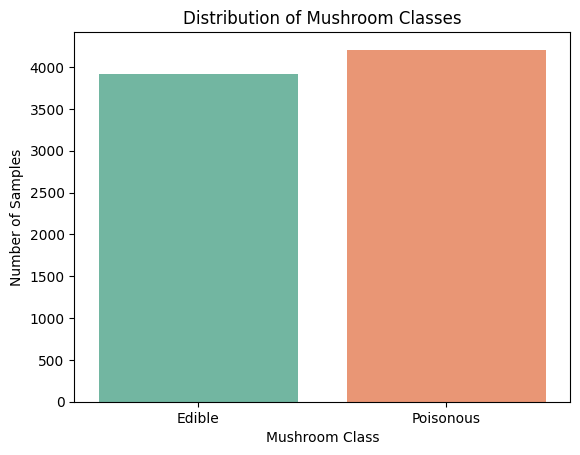

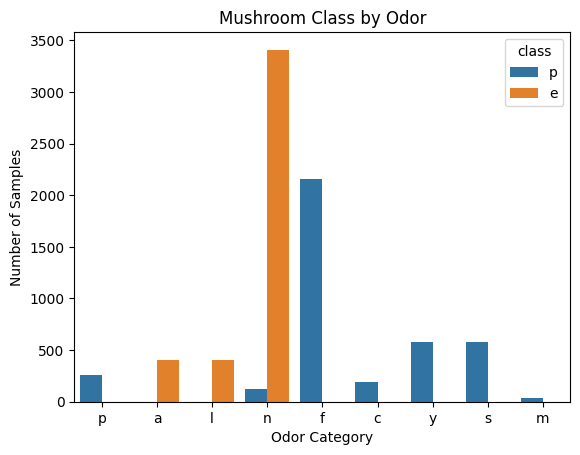

In [ ]:
# Check missing values
print("Missing values:")
print((df == '?').sum().sort_values(ascending=False).head(10))

# Visualize edible and poisonous mushrooms
sns.countplot(data=df, x='class', hue='class', palette='Set2', legend=False)

plt.xticks([0, 1], ['Edible', 'Poisonous'])
plt.xlabel('Mushroom Class')
plt.ylabel('Number of Samples')
plt.title('Distribution of Mushroom Classes')
plt.show()

# Compare odor and mushroom class
sns.countplot(data=df, x='odor', hue='class')

plt.xlabel('Odor Category')
plt.ylabel('Number of Samples')
plt.title('Mushroom Class by Odor')
plt.show()

In [ ]:
X = df.drop(columns=['class'])
y = df['class']

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

encoder = OrdinalEncoder(
    handle_unknown='use_encoded_value',
    unknown_value=-1
)

X_train_encoded = encoder.fit_transform(X_train)
X_test_encoded = encoder.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nClass encoding:")
print(dict(enumerate(label_encoder.classes_)))

Training samples: 6499
Testing samples: 1625

Class encoding:
{0: 'e', 1: 'p'}


In [ ]:
# Create and train the Naive Bayes model
nb_model = CategoricalNB(
    min_categories=[
        len(categories) + 1
        for categories in encoder.categories_
    ]
)

X_train_nb = X_train_encoded + 1
X_test_nb = X_test_encoded + 1

nb_model.fit(X_train_nb, y_train)

# Make predictions
y_pred = nb_model.predict(X_test_nb)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Naive Bayes Accuracy: {accuracy:.2%}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_
))

Naive Bayes Accuracy: 94.58%

Classification Report:
              precision    recall  f1-score   support

           e       0.91      0.99      0.95       842
           p       0.99      0.90      0.94       783

    accuracy                           0.95      1625
   macro avg       0.95      0.94      0.95      1625
weighted avg       0.95      0.95      0.95      1625



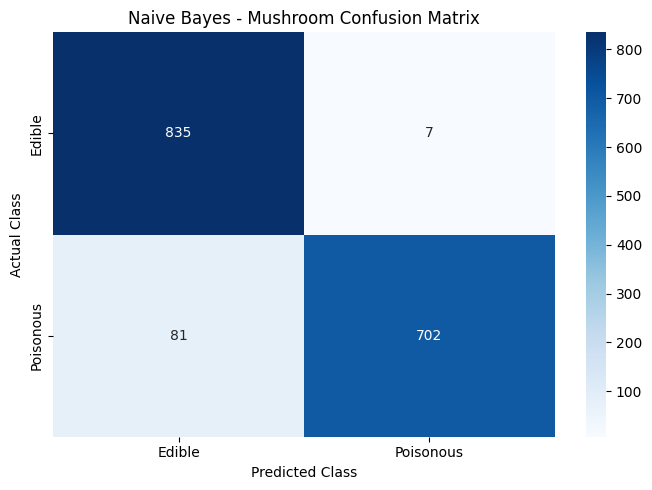

Poisonous mushrooms predicted as edible: 81
Edible mushrooms predicted as poisonous: 7


In [ ]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Edible', 'Poisonous'],
    yticklabels=['Edible', 'Poisonous']
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.title('Naive Bayes - Mushroom Confusion Matrix')
plt.tight_layout()
plt.show()

print("Poisonous mushrooms predicted as edible:", cm[1, 0])
print("Edible mushrooms predicted as poisonous:", cm[0, 1])

In [ ]:
# Select three samples from the test dataset
new_mushrooms = X_test.iloc[:3]

# Encode using the existing encoder
new_encoded = encoder.transform(new_mushrooms) + 1

predictions = nb_model.predict(new_encoded)
probabilities = nb_model.predict_proba(new_encoded)

predicted_labels = label_encoder.inverse_transform(predictions)
actual_labels = label_encoder.inverse_transform(y_test[:3])

print("Mushroom Classification Results\n")

for i in range(len(new_mushrooms)):
    print(f"Mushroom Sample {i+1}")
    print("Predicted:", predicted_labels[i])
    print("Actual:", actual_labels[i])
    print("Probability Edible:", f"{probabilities[i][0]:.2%}")
    print("Probability Poisonous:", f"{probabilities[i][1]:.2%}")
    print("-" * 35)

Mushroom Classification Results

Mushroom Sample 1
Predicted: p
Actual: p
Probability Edible: 0.00%
Probability Poisonous: 100.00%
-----------------------------------
Mushroom Sample 2
Predicted: e
Actual: p
Probability Edible: 63.09%
Probability Poisonous: 36.91%
-----------------------------------
Mushroom Sample 3
Predicted: e
Actual: e
Probability Edible: 100.00%
Probability Poisonous: 0.00%
-----------------------------------


##Summary
I used the Naïve Bayes algorithm to predict whether a mushroom is edible or poisonous based on its physical characteristics.

The dataset contains 8,124 mushroom samples with 22 features, including odor, cap shape, and color. I used 80% of the data to train the model and the remaining 20% to test its performance.

The model achieved an accuracy of 94.58%, correctly classifying approximately 1,537 out of 1,625 mushrooms. The model correctly identified about 99% of edible mushrooms and 90% of poisonous mushrooms.

Source: https://archive.ics.uci.edu/dataset/73/mushroom